# Creating an iES experiment

The iterative ensemble smoother as implemented in PEST++ is an ensemble-based version of the Gauss-Levenberg-Marquardt (GLM), gradient-based regression technique for minimizing a weighted sum-of-squared residuals objective function for history matching. This approach is similar to an Ensemble Kalman Filter in which all the data are assimilated in a single batch.

We adopt the following steps for performing history matching using iES. 

<img src="./images/iES_workflow.png" width="500"/>

In the previous lesson we performed the prior MC run, and in this lesson we will go through the rest of the steps shown in the flowchart. 

In [1]:
import pandas as pd
import pyemu
import sys
import shutil
import os
import numpy as np
from pathlib import Path
from datetime import datetime as dt
import matplotlib.pyplot as plt
from pytsproc import filters, series_metrics
plt.rcParams['font.size']=12
%matplotlib inline
import warnings
warnings.simplefilter("ignore", DeprecationWarning)

## **Step 1. Define the working directories**

In [2]:
# Define the path to the single model run PEST++ host directory 
singledir = Path('/glade/u/home/arezoo/wrf_hydro_training/output/pestpp/lesson1/host')

# Define the path to the prior MC PEST++ host directory 
priordir = Path('/glade/u/home/arezoo/wrf_hydro_training/output/pestpp/lesson2/host') 

# Define where the iES work directory would be
iesdir = Path('/glade/u/home/arezoo/wrf_hydro_training/output/pestpp/lesson3/iES_Run') 

# Define where to save plots generated in this notebook
plotdir = Path('/glade/u/home/arezoo/wrf_hydro_training/output/pestpp/lesson3/plots')

In [3]:
if not os.path.exists(plotdir):
    plotdir.mkdir(parents=True)

## **Step 2.  Define the calibration, validation and spin up period.** 
Below is a short description of 
* burn_in: this is the time period that the model simulations will be discarded. We usually define a period where the model is run to adjust to the change of the parameters and avoid model instability, this period is not used in the calibration or validation of the model. In a real experiment, this could be a year. 
* calibration: this is the period used for parameter estimation.
* validation: the independent period used to verify the model performance after performing history matching. 

In [4]:
simulation_start_date = '2018-08-01'
valid_start_date = '2018-08-02'
calib_start_date = '2018-08-10'

## **Step 3. Read in the PESTPP control file from the single model run**

We could read the information of a given model run using PyEMU library, and make adjustment and modifications and create a new model run. 
Here we are attempting to follow the steps in flowchart in blue using the single model run. 
Let us read the experiment, look at the parameters and the observation used in parameter estimation. 


In [5]:
pst = pyemu.Pst(str(singledir / 'wrfpst.pst'), resfile=str(singledir / 'wrfpst.base.rei'))

Parameters used in the history matching experiment is saved in the `parameter_data`. 

In [6]:
pst.parameter_data.head()

,parnme,partrans,parchglim,parval1,parlbnd,parubnd,pargp,scale,offset,dercom
parnme,,,,,,,,,,
bexp,bexp,none,relative,1.00,0.4,1.9,group1,1.0,0.0,1
smcmax,smcmax,none,relative,1.00,0.8,1.2,group1,1.0,0.0,1
dksat,dksat,none,relative,1.00,0.2,10.0,group1,1.0,0.0,1
refkdt,refkdt,fixed,relative,1.00,0.1,4.0,group1,1.0,0.0,1
slope,slope,none,relative,0.33,0.0,1.0,group1,1.0,0.0,1


Observation dataset used in the history matching is saved in the `observation_data`. 

In [7]:
pst.observation_data.head()

,obsnme,obsval,weight,obgnme
obsnme,,,,
kge,kge,1.000000,0.0,streamflow
obs_20180801_010000,obs_20180801_010000,9.231292,1.0,streamflow
obs_20180801_020000,obs_20180801_020000,9.089708,1.0,streamflow
obs_20180801_030000,obs_20180801_030000,8.778223,1.0,streamflow
obs_20180801_040000,obs_20180801_040000,8.636638,1.0,streamflow


We could display different components of the phi calculation, here we had only one obsevration category called `streamflow`. In this lesson we will define more groups and weigh them differently to form the objective function. 

<Axes: >

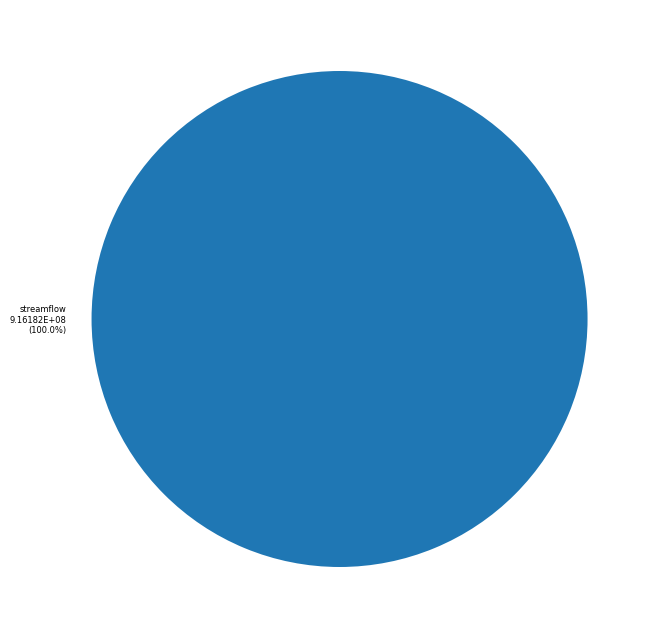

In [8]:
pst.plot(kind='phi_pie')

## **Step4. Categorize the observation**

Let's start with defining the burnin and validation period first. 

In [9]:
# make a copy of the observation data 
obs = pst.observation_data.copy()

obs.loc[obs.obsval==-9999, 'obsval'] = np.nan

def parsename(cn):
    '''
    parse the dates from the WRF_hydro obs names
    '''
    tmp = cn.replace('obs_','')
    return dt.strptime(tmp, '%Y%m%d_%H0000')

# get the time from the name of the observation obs_YYYYmmdd_hhMMSS
obs['dtime'] = [np.nan] + [parsename(i) for i in obs.iloc[1:].index]

# trim off the burn-in period
obs.loc[obs.dtime<valid_start_date, 'obgnme'] = 'burn_in'

# label the validation period
obs.loc[(obs.dtime >= valid_start_date) & (obs.dtime < calib_start_date), 'obgnme'] = 'validation'

In [10]:
# copy over the updated obsgroups to the original
pst.observation_data.obgnme = obs.obgnme.values

obgnames = obs.obgnme.copy()

obgnames.loc['kge'] = 'kge'
print(obgnames.unique())

obs['discharge'] = obs.obsval

['kge' 'burn_in' 'validation' 'streamflow']


In [11]:
obs.iloc[:]

,obsnme,obsval,weight,obgnme,dtime,discharge
obsnme,,,,,,
kge,kge,1.000000,0.0,streamflow,NaT,1.000000
obs_20180801_010000,obs_20180801_010000,9.231292,1.0,burn_in,2018-08-01 01:00:00,9.231292
obs_20180801_020000,obs_20180801_020000,9.089708,1.0,burn_in,2018-08-01 02:00:00,9.089708
obs_20180801_030000,obs_20180801_030000,8.778223,1.0,burn_in,2018-08-01 03:00:00,8.778223
obs_20180801_040000,obs_20180801_040000,8.636638,1.0,burn_in,2018-08-01 04:00:00,8.636638
...,...,...,...,...,...,...
obs_20180831_200000,obs_20180831_200000,6.597825,1.0,streamflow,2018-08-31 20:00:00,6.597825
obs_20180831_210000,obs_20180831_210000,6.711093,1.0,streamflow,2018-08-31 21:00:00,6.711093
obs_20180831_220000,obs_20180831_220000,7.079212,1.0,streamflow,2018-08-31 22:00:00,7.079212


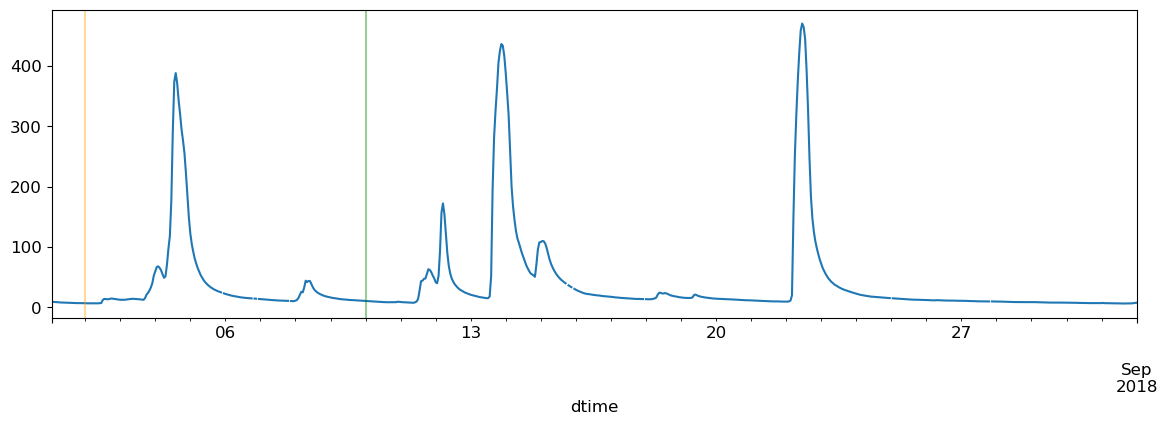

In [12]:
 # set index to datetime
obs.set_index('dtime', drop=False, inplace=True)

# plot the full period of simulation
ax = obs.discharge[1:].plot(figsize=(14,4))
ax.axvline('2018-08-02', c='orange', alpha=.4);
ax.axvline('2018-08-10', c='green', alpha=.4);

### For next analysis, trim off kge and burn in and validation period

In [13]:
# trim off the observation and only keep the calibration period
obs = obs.iloc[1:].loc[obs.dtime>= calib_start_date]

# Finding the NaN streamflows
print(obs.loc[obs.discharge.isnull()])

# fill in the nan discharge values with linear interpolatoin
obs['discharge']=obs.discharge.interpolate()

# flip back the NaN obs values to -9999
obs.loc[obs.obsval.isnull(), 'obsval'] = -9999

                                  obsnme  obsval  weight      obgnme  \
dtime                                                                  
2018-08-15 18:00:00  obs_20180815_180000     NaN     1.0  streamflow   
2018-08-15 22:00:00  obs_20180815_220000     NaN     1.0  streamflow   
2018-08-17 23:00:00  obs_20180817_230000     NaN     1.0  streamflow   
2018-08-25 00:00:00  obs_20180825_000000     NaN     1.0  streamflow   
2018-08-27 20:00:00  obs_20180827_200000     NaN     1.0  streamflow   

                                  dtime  discharge  
dtime                                               
2018-08-15 18:00:00 2018-08-15 18:00:00        NaN  
2018-08-15 22:00:00 2018-08-15 22:00:00        NaN  
2018-08-17 23:00:00 2018-08-17 23:00:00        NaN  
2018-08-25 00:00:00 2018-08-25 00:00:00        NaN  
2018-08-27 20:00:00 2018-08-27 20:00:00        NaN  


### Quantiles

In this step, we will define the streamflow quantiles and apply and categorize the flow based on which quantiles if falls into. 


In [14]:
# set number of quantiles
quantiles=4

quantile_vals = [obs.discharge.quantile(((i+1)/quantiles)) for i in range(quantiles)]

quantile_vals

#identify the locations of the quantiles
obs['quantile_grp'] = np.nan
for i,q_current in zip(range(1,quantiles+1),quantile_vals):
    if i==1:
        obs.loc[obs.discharge<=q_current, 'quantile_grp'] = 'q1'
    else:
        obs.loc[(obs.discharge <= q_current) & (obs.discharge>quantile_vals[i-2]), 'quantile_grp'] = f'q{i}'
        

assert len(obs.loc[obs.quantile_grp.isnull()]) == 0

obs.quantile_grp.unique()

for cn,cg in obs.groupby('quantile_grp'):
    print(cn, len(cg))

q1 134
q2 132
q3 132
q4 131


/glade/derecho/scratch/arezoo/tmp/ipykernel_1988836/1720209599.py:12: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'q1' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.


### Event based weighting

Next, we will define events using the function `hydro_events`, this function provided the start and end date of events as well as peak time. 

In [15]:
Qhe = series_metrics.hydro_events(obs,  wlen=50, prominence=25, height=2)

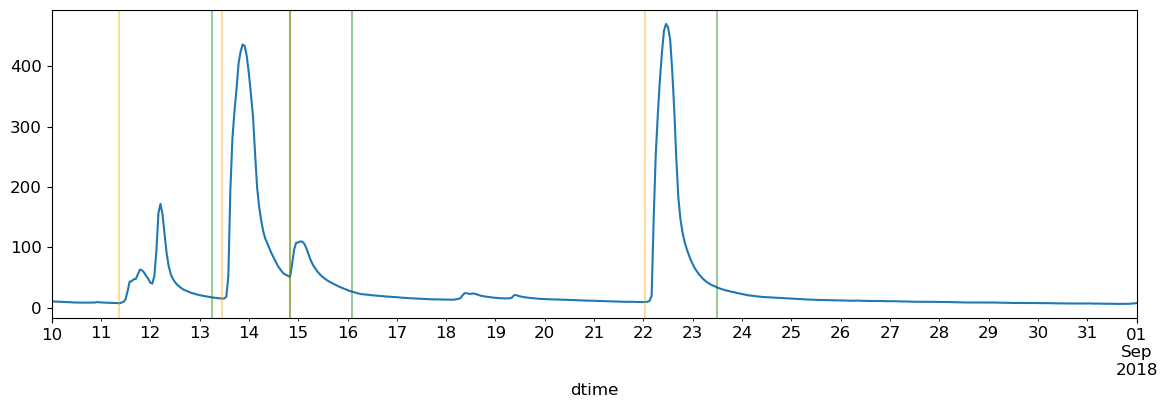

In [16]:
 ax = obs.discharge.plot(figsize=(14,4))
 [ax.axvline(i, c='orange', alpha=.4) for i in Qhe[1]['event_starts']];
 [ax.axvline(i, c='green', alpha=.4) for i in Qhe[1]['event_ends']];


In [17]:
Qhe[1]

{'event_starts': DatetimeIndex(['2018-08-11 09:00:00', '2018-08-13 11:00:00',
                '2018-08-14 20:00:00', '2018-08-22 01:00:00'],
               dtype='datetime64[ns]', name='dtime', freq=None),
 'event_ends': DatetimeIndex(['2018-08-13 06:00:00', '2018-08-14 20:00:00',
                '2018-08-16 02:00:00', '2018-08-23 12:00:00'],
               dtype='datetime64[ns]', name='dtime', freq=None)}

In [18]:
# Assign the new group naming 
obs.obgnme = obs.quantile_grp
for st, en in zip(Qhe[1]['event_starts'], Qhe[1]['event_ends']):
    obs.loc[(obs.index>=st) & (obs.index<=en), 'obgnme'] = 'event'
obs.loc[obs.obgnme=='event']

,obsnme,obsval,weight,obgnme,dtime,discharge,quantile_grp
dtime,,,,,,,
2018-08-11 09:00:00,obs_20180811_090000,7.588915,1.0,event,2018-08-11 09:00:00,7.588915,q1
2018-08-11 10:00:00,obs_20180811_100000,8.495054,1.0,event,2018-08-11 10:00:00,8.495054,q1
2018-08-11 11:00:00,obs_20180811_110000,9.825946,1.0,event,2018-08-11 11:00:00,9.825946,q2
2018-08-11 12:00:00,obs_20180811_120000,14.186740,1.0,event,2018-08-11 12:00:00,14.186740,q2
2018-08-11 13:00:00,obs_20180811_130000,27.920411,1.0,event,2018-08-11 13:00:00,27.920411,q4
...,...,...,...,...,...,...,...
2018-08-23 08:00:00,obs_20180823_080000,40.209923,1.0,event,2018-08-23 08:00:00,40.209923,q4
2018-08-23 09:00:00,obs_20180823_090000,37.944575,1.0,event,2018-08-23 09:00:00,37.944575,q4
2018-08-23 10:00:00,obs_20180823_100000,36.528733,1.0,event,2018-08-23 10:00:00,36.528733,q4


### Now bring the new observation group names back to `pst.observation_data`

In [19]:
pst.observation_data.loc[obs.obsnme, 'obgnme'] = obs.obgnme.values

# there is only the KGE field which has the group name of the streamflow
pst.observation_data.loc[pst.observation_data.obgnme=='streamflow', 'obgnme'] = 'kge'
pst.observation_data.loc[pst.observation_data['obgnme'] == 'kge', 'weight'] = 0

pst.observation_data.loc[pst.observation_data.index.isin(obs.obsnme), 'obgnme'] = obs.obgnme.values

pst.observation_data.loc[pst.observation_data['obsval'] == -9999, 'obgnme'] = 'burn_in'
pst.observation_data.loc[pst.observation_data['obsval'] == -9999, 'weight'] = 0
pst.observation_data.loc[pst.observation_data['obgnme'] == 'burn_in', 'weight'] = 0
pst.observation_data

,obsnme,obsval,weight,obgnme
obsnme,,,,
kge,kge,1.000000,0.0,kge
obs_20180801_010000,obs_20180801_010000,9.231292,0.0,burn_in
obs_20180801_020000,obs_20180801_020000,9.089708,0.0,burn_in
obs_20180801_030000,obs_20180801_030000,8.778223,0.0,burn_in
obs_20180801_040000,obs_20180801_040000,8.636638,0.0,burn_in
...,...,...,...,...
obs_20180831_200000,obs_20180831_200000,6.597825,1.0,q1
obs_20180831_210000,obs_20180831_210000,6.711093,1.0,q1
obs_20180831_220000,obs_20180831_220000,7.079212,1.0,q1


### Now let us check the contribution of each category to the phi 

<Axes: >

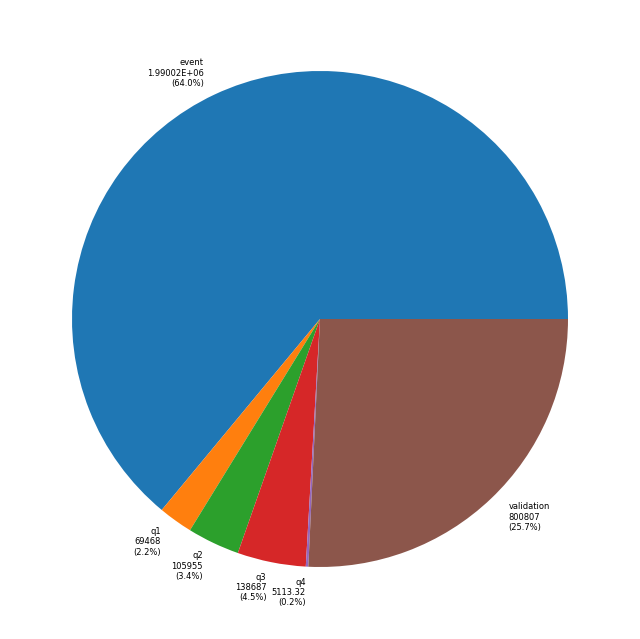

In [20]:
pst.plot(kind='phi_pie')

## **Step 5. Reweight observations based on the 10% CV**

In [21]:
pst.observation_data.loc[pst.observation_data.obgnme != 'kge' , 'weight'] = \
    10 / pst.observation_data.loc[pst.observation_data.obgnme != 'kge' , 'obsval']

### let us set the weights for the burn in and validation period to 0 also so they do not contibute to the calibration of the phi.

In [22]:
pst.observation_data.loc[pst.observation_data['obsval'] == -9999, 'obgnme'] = 'burn_in'
pst.observation_data.loc[pst.observation_data['obsval'] == -9999, 'weight'] = 0

pst.observation_data.loc[pst.observation_data.obgnme == 'burn_in' , 'weight'] = 0 
pst.observation_data.loc[pst.observation_data.obgnme == 'validation' , 'weight'] = 0 

pst.res['weight'] = pst.observation_data.weight.values # have to trick the residuals to know about new obsgp

In [23]:
pst.observation_data.head()

,obsnme,obsval,weight,obgnme
obsnme,,,,
kge,kge,1.000000,0.0,kge
obs_20180801_010000,obs_20180801_010000,9.231292,0.0,burn_in
obs_20180801_020000,obs_20180801_020000,9.089708,0.0,burn_in
obs_20180801_030000,obs_20180801_030000,8.778223,0.0,burn_in
obs_20180801_040000,obs_20180801_040000,8.636638,0.0,burn_in


In [24]:
pst.observation_data.loc[pst.observation_data.obgnme=='streamflow']

,obsnme,obsval,weight,obgnme
obsnme,,,,


<Axes: >

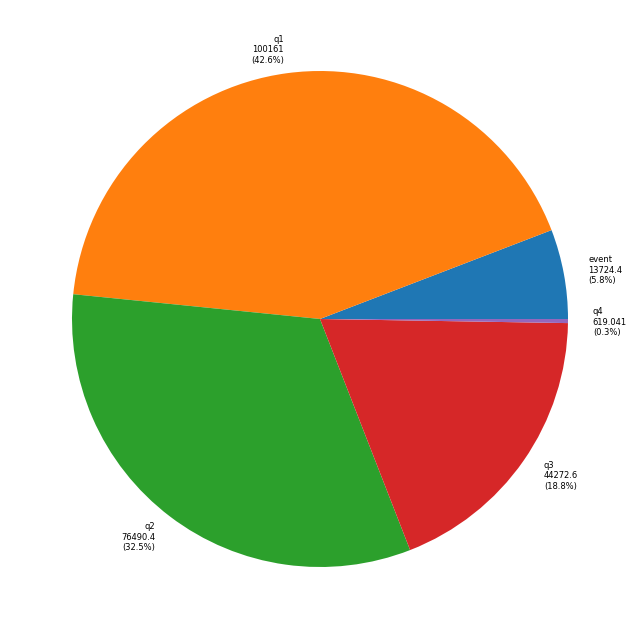

In [25]:
pst.plot(kind='phi_pie')

## **Step 6. Provide weighting for each category**

The objective function for iES is the weighted sum of squared errors. While this makes up a single quantity, the weights–assigned to each observation–are used to balance the contribution of various observation categories (e.g. streamflows of different flow regimes, peaks, recession periods, and others) to the objective function. This allows tuning the history matching process to estimate parameters appropriate for a specific output category. In this training, we are targeting a superior performance during the events and therefore, providing half of the weights to the `event` category. 

In [26]:
# make sure there were no 0 flow values which would result in infinite weights
assert np.unique(np.isinf(pst.observation_data.weight.values)) == np.array([False])

In [27]:
new_portions = {'burn_in': 0.0,
 'validation':0,
 'event': 0.5,
 'kge': 0.0,
 'q1': 0.1,
 'q2': 0.1,
 'q3': 0.1,
 'q4': 0.2}

In [28]:
new_portions = {k:v*pst.nnz_obs for k,v in 
                new_portions.items()}

In [29]:
pst.res['group'] = pst.observation_data.obgnme.values # have to trick the residuals to know about new obsgp
pst.res['weight'] = pst.observation_data.weight.values # have to trick the residuals to know about new obsgp
pst.adjust_weights(obsgrp_dict=new_portions)

<Axes: >

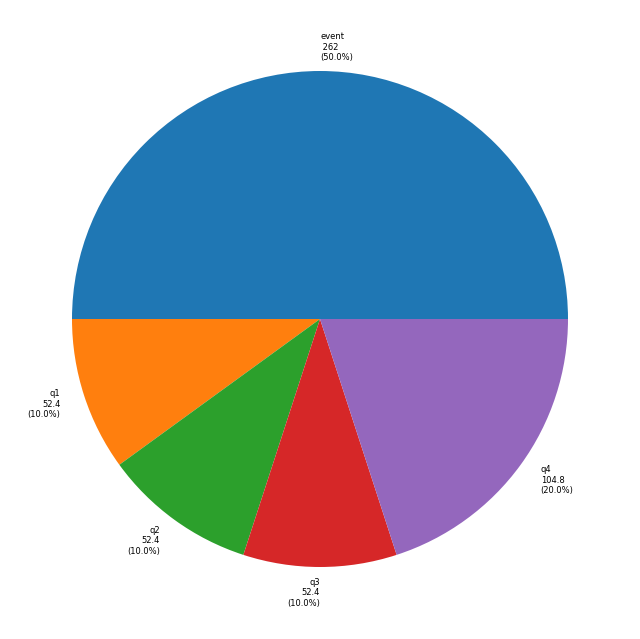

In [30]:
pst.plot(kind='phi_pie')

## **Step 7. Recalculate the objective function (phi) with new weights to perform rejection sampling**

In [31]:
obens = pyemu.ObservationEnsemble.from_csv(pst, str(priordir / 'wrfpst.0.obs.csv'),
                                           index_col=0, dtype={'real_name':str})

In [32]:
obens.head()

,kge,obs_20180801_010000,obs_20180801_020000,obs_20180801_030000,obs_20180801_040000,obs_20180801_050000,obs_20180801_060000,obs_20180801_070000,obs_20180801_080000,obs_20180801_090000,...,obs_20180831_150000,obs_20180831_160000,obs_20180831_170000,obs_20180831_180000,obs_20180831_190000,obs_20180831_200000,obs_20180831_210000,obs_20180831_220000,obs_20180831_230000,obs_20180901_000000
real_name,,,,,,,,,,,,,,,,,,,,,
0,-0.101496,169.8320,550.6270,2194.970,2156.280,1826.250,1328.120,987.375,778.774,648.067,...,27.55500,27.49190,27.42860,27.36540,27.30220,27.23920,27.17640,27.1139,27.05220,26.99260
1,0.192742,68.2568,78.6837,281.612,609.181,590.537,514.209,440.346,365.925,300.365,...,16.20340,16.12120,16.04630,15.96760,15.89550,15.83890,15.79290,16.0349,16.01900,16.14130
2,0.203344,115.8530,178.9230,1105.570,1254.600,1084.920,872.069,654.234,493.091,382.021,...,17.38410,17.29970,17.21620,17.13350,17.05180,16.98190,16.93020,16.9818,16.97170,17.03130
3,0.352597,139.4770,392.6740,1780.290,2175.060,2150.290,1750.870,1392.870,1150.120,978.281,...,5.57924,5.56769,5.55505,5.54547,5.55797,5.60688,5.68241,5.8006,5.97513,6.20091
4,0.107574,131.5280,276.1590,1382.630,1450.120,1264.190,963.871,699.656,519.035,398.763,...,10.48650,10.48300,10.47890,10.47460,10.49530,10.62810,10.64820,11.2568,11.30420,11.68940


In [33]:
phi = obens.phi_vector
print(len(phi))

30


<Axes: >

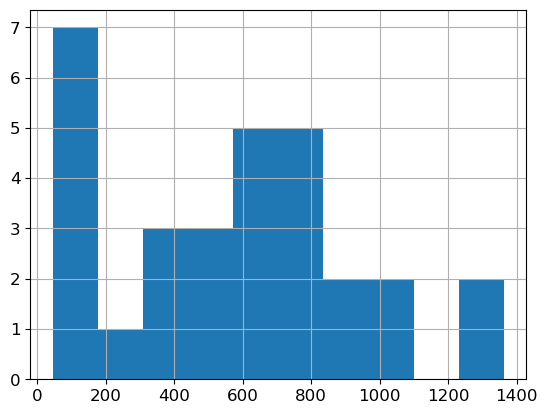

In [34]:
#No noise
phi.hist(bins=10)

## **Step 7. Perform rejection sampling Based on Prior MC runs**

To perform rejection sampling we would look into the objective function calculated using the new weighting, and define a cutoff to remove the outliers. In this small exmaple, we probably do not benefit from rejection sampling. This is only for training purposes. 

In [35]:
phicutoff = 1200

In [36]:
print(len(phi))
phi = phi.loc[phi<phicutoff]
print(len(phi))


30
28


In [37]:
reals_to_keep = phi.index.values
reals_to_keep

array(['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12',
       '13', '14', '15', '16', '17', '18', '19', '20', '22', '23', '24',
       '25', '27', '28', 'base'], dtype=object)

In [38]:
prior_pars = pd.read_csv(priordir / 'wrfpst.0.par.csv', index_col=0, dtype={'real_name':str})
pp = prior_pars.loc[reals_to_keep]
pp.index = [str(i) for i in range(len(pp)-1)] + ['base']
pp.to_csv(
            priordir/'wrfpst.starting_pars.csv')
oe = obens._df.loc[reals_to_keep].copy()
oe.index = pp.index
oe.to_csv(
            priordir/'wrfpst.starting_obs.csv')

## **Step 8. Create iES run directory**
Let us first Delete iES folder if it is already exist.

In [39]:
if os.path.exists(Path(iesdir)):
    shutil.rmtree(iesdir)

Let us create the run directory similar by copying the single model run directory. 

In [40]:
!cp -r ~/wrf_hydro_training/output/pestpp/lesson1/Single_Model_Run/ ~/wrf_hydro_training/output/pestpp/lesson3/iES_Run

Now we could make the modification to the PEST++ control files and overwrite the files in the iES run directly. Let us start with preparing the new starting observation and parameter files for the experiment. 

In [41]:
prior_pars = pd.read_csv(priordir / 'wrfpst.0.par.csv', index_col= 0, dtype={'real_name':str})
pp = prior_pars.loc[reals_to_keep]
pp.index = [str(i) for i in range(len(pp)-1)] + ['base']
pp.to_csv(iesdir/'wrfpst.starting_pars.csv')
oo = obens._df.loc[reals_to_keep].copy()
oo.index = pp.index
oo.to_csv(iesdir/'wrfpst.starting_obs.csv')

### User specified observation file with added noise
The iES algorithm is predicated on the assumption that the ensemble of observation measurement values is corrupted by noise. 
However, PEST++ also includes an option to ignore noise in the observations 
(ies_no_noise = true, and no provided observation ensemble). 
If the noise is ignored, the ensemble of observations will be all identical members. 
Next available option is to generate the noise using the existing framework in PEST++ 
(ies_no_noise = false, and no provided observation ensemble). 
In this case, error in observations are additive noise sampled from an assumed pdf of observation error. 
The time series generated using this approach are usually not smooth, since the additive noise could be a positive 
value at one time step and reverse sign in the next time step. 
Ideally, we would like to have smooth hydrographs, in particular to preserve the diurnal cycles properly in the model. 
Alternative method is to supply an external text file containing observation realizations with added noise. 
Using this feature, we could provide the observation ensemble with temporally auto-correlated additive noise. 
Here, we have created an observation file with the added noise which will be used instead of the single observation time series. Note the observation was created for a case with 300 ensembles, however, due to compute limitations here, we are only using a subset of those ensemble members.

In [42]:
obs_noise_ens = pd.read_csv('/glade/u/home/arezoo/wrf_hydro_training/example_case/calibration/PESTPP/OBS/obs_noise_01473000_300ens_201808.csv', 
                            index_col = 'real_name', dtype={'real_name':str})
one = obs_noise_ens.loc[reals_to_keep].copy()
one.index=pp.index
one.to_csv(iesdir/'wrfpst.starting_obs+noise.csv')

In [43]:
obs_noise_ens.head()

,kge,obs_20180801_000000,obs_20180801_010000,obs_20180801_020000,obs_20180801_030000,obs_20180801_040000,obs_20180801_050000,obs_20180801_060000,obs_20180801_070000,obs_20180801_080000,...,obs_20180831_150000,obs_20180831_160000,obs_20180831_170000,obs_20180831_180000,obs_20180831_190000,obs_20180831_200000,obs_20180831_210000,obs_20180831_220000,obs_20180831_230000,obs_20180901_000000
real_name,,,,,,,,,,,,,,,,,,,,,
0,1,9.230433,9.075582,8.688337,8.476681,8.251564,8.136198,8.114034,7.852902,7.973340,...,6.548479,6.614118,6.724229,6.679672,6.810860,6.877858,6.989337,7.300314,7.630498,7.870579
1,1,9.691547,9.471386,9.184341,8.951908,8.788736,8.488553,8.438145,7.977647,8.057205,...,6.405475,6.655819,6.608830,6.551624,6.478994,6.628006,6.522572,6.994974,7.360141,7.580284
2,1,10.130309,9.826260,9.574296,9.176957,8.872961,8.661179,8.520047,7.958272,7.891716,...,6.171724,6.196976,6.196725,6.107964,6.190899,6.307619,6.408841,6.624100,6.874640,7.191378
3,1,9.745304,9.402980,9.333376,8.893671,8.668228,8.580845,8.483005,8.225309,8.202840,...,6.167926,6.325047,6.331970,6.304950,6.390871,6.460110,6.619653,6.784167,7.201871,7.582315
4,1,10.530177,10.185508,9.860199,9.282536,9.142928,8.880888,8.562038,8.018159,8.231455,...,6.889802,6.975537,7.069953,6.944789,6.929982,7.170007,7.336687,7.707118,8.041246,8.192260


### Modify the PEST++ Control File
Last but not the least, we want to modify the entries of the PEST++ control file and set some problem specific PESTPP-IES settings

In [44]:
len(reals_to_keep)

28

In [45]:
pst.control_data.noptmax=2
pst.pestpp_options["ies_num_reals"] = len(reals_to_keep)
pst.pestpp_options["overdue_giveup_minutes"] = 200
pst.pestpp_options["ies_no_noise"] = 'false'
pst.pestpp_options["ies_observation_ensemble"] = 'wrfpst.starting_obs+noise.csv'
pst.pestpp_options["ies_restart_observation_ensemble"] = 'wrfpst.starting_obs.csv'
pst.pestpp_options["ies_parameter_ensemble"] = 'wrfpst.starting_pars.csv'

pst.write(iesdir/'wrfpst.pst', version=2)

noptmax:2, npar_adj:19, nnz_obs:524


## **Step 9. Running PEST++ with WRF-Hydro**



In [46]:
# rel_path (str, optional) – the relative path to where pest(++) should be run from within the worker_dir, defaults to the uppermost level of the worker dir. 

pyemu.utils.os_utils.start_workers(worker_dir = "/glade/u/home/arezoo/wrf_hydro_training/output/pestpp/lesson3/iES_Run", 
                                   exe_rel_path = "pestpp-ies", 
                                   pst_rel_path = "wrfpst.pst", 
                                   num_workers=8, 
                                   worker_root='/glade/u/home/arezoo/wrf_hydro_training/output/pestpp/lesson3/',
                                   master_dir = "/glade/u/home/arezoo/wrf_hydro_training/output/pestpp/lesson3/host",
                                   port=4004, 
                                   verbose = True, 
                                   cleanup = False)


master:./pestpp-ies wrfpst.pst /h :4004 in /glade/u/home/arezoo/wrf_hydro_training/output/pestpp/lesson3/host


             pestpp-ies: a GLM iterative ensemble smoother

                   by the PEST++ development team


version: 5.2.9
binary compiled on Jan 18 2024 at 16:01:42

started at 10/29/26 18:09:50
...processing command line: ' ./pestpp-ies wrfpst.pst /h :4004'
...using panther run manager in master mode using port 4004

using control file: "wrfpst.pst"
in directory: "/glade/work/arezoo/USGS_NY_Flood/wrf_hydro_training/output/pestpp/lesson3/host"
on host: "dec2435"

processing control file wrfpst.pst


:~-._                                                 _.-~:
: :.~^o._        ________---------________        _.o^~.:.:
 : ::.`?88booo~~~.::::::::...::::::::::::..~~oood88P'.::.:
 :  ::: `?88P .:::....         ........:::::. ?88P' :::. :
  :  :::. `? .::.            . ...........:::. P' .:::. :
   :  :::   ... ..  ...       .. .::::......::.   :::. :
   `  :' .... ..  .:::::.

## **Step 10. Let check the run directory**

In [ ]:
%%bash 
ls  ~/wrf_hydro_training/output/pestpp/lesson3/

In [ ]:
%%bash 
ls  ~/wrf_hydro_training/output/pestpp/lesson3/host

The successful finish message of PEST++ could be found in the wrfpst.rmr file.

In [ ]:
%%bash 
cat   ~/wrf_hydro_training/output/pestpp/lesson3/host/wrfpst.rec | tail -n 5

Let us check the content of the workder folder.

In [ ]:
%%bash 
ls   ~/wrf_hydro_training/output/pestpp/lesson3/worker_0/

Now we could continue to the next lesson and verify the results of the history matching exercise using the iES. 